In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from astropy.table import Table
from PyAstronomy import pyasl
from breidablik.interpolate.nlte import Nlte
import breidablik.interpolate.spectra as brei
import ast

## Using Ella's 3D NLTE code to get corrections for my observed Li abundances

Applying NLTE corrections to my measured abundance

In [45]:
# Setting up the stellar parameters for my star
abund_li_1DLTE = 1.98
abund_li_1DLTE_err = 0.03
teff = 5000
logg = 1.85
feh = -3.37
feh_err = 0.07

# Initialising the model
model = Nlte()

# Getting 3D NLTE corrections for Li
nlte_corr = model.nlte_correction(eff_t = teff, 
                                  surf_g = logg,
                                  met = feh,
                                  abundance = abund_li_1DLTE,
                                  center = 670.9659)

# Applying correction to the observed Li abundance
abund_li_3DNLTE = abund_li_1DLTE + nlte_corr

# Getting errors for the 3D NLTE abundance
abund_li_3DNLTE_err = np.sqrt(abund_li_1DLTE_err**2 + feh_err**2)
print(f"3D NLTE Li abundance: {abund_li_3DNLTE:.2f} ± {abund_li_3DNLTE_err:.2f}")
print(nlte_corr)


3D NLTE Li abundance: 1.90 ± 0.08
-0.08041538073153998


Plotting the fit

,fit_wave,line,abund_xfe,err,chisqr,weight,fit_flux,obs_flux,obs_wave,abund_xh
0,"[[6700.098520916285, 6700.298392598197, 6700.4...",Li_6707.813,4.364162,0.020321,54.276622,2421.660538,"[[0.9840029100457197, 0.9840231821476424, 0.98...","[[0.972075557950521, 0.9688362470442071, 0.971...","[[6695.101728868589, 6695.301600550499, 6695.5...",0.993131


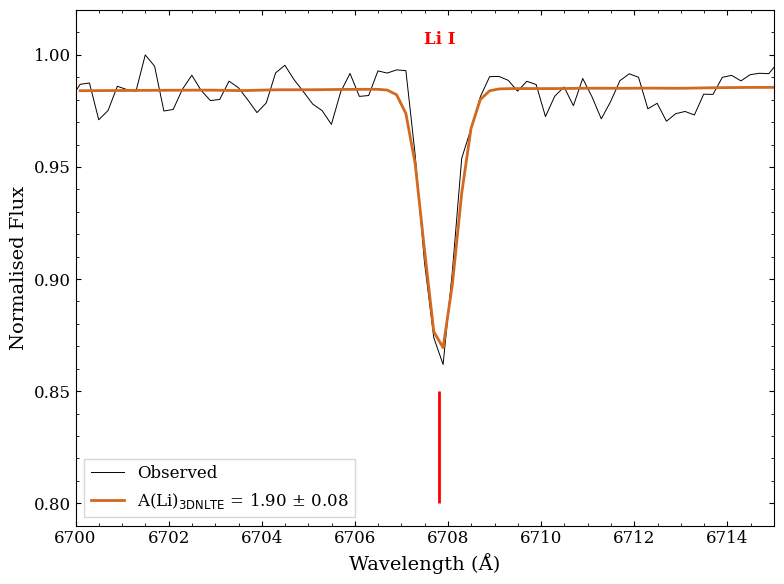

In [44]:
# Loading the data
spec_df = pd.read_csv("/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/ra_1633-2814_s130/Li_I/iter_1/Li_results.csv")
display(spec_df)

fitwave = ast.literal_eval(spec_df['fit_wave'].to_numpy()[0])[0]
fitflux = ast.literal_eval(spec_df['fit_flux'].to_numpy()[0])[0]
obswave = ast.literal_eval(spec_df['obs_wave'].to_numpy()[0])[0]
obsflux = ast.literal_eval(spec_df['obs_flux'].to_numpy()[0])[0]

# Plotting
plt.figure(figsize=(8, 6))
plt.plot(obswave, obsflux, label='Observed', color='black', linewidth=0.7)
plt.plot(fitwave, fitflux, label=r'A(Li)$_{\rm 3D NLTE}$ = 1.90 ± 0.08', color='chocolate', linewidth=2)

plt.vlines(x=6707.814, ymin=0.8, ymax=0.85, color='red', linewidth=2)
plt.text(6707.814, 1.005, 'Li I', color='red', fontsize=12, ha='center', fontweight='bold')

plt.xlabel('Wavelength (Å)')
plt.ylabel('Normalised Flux')
plt.xlim(6700, 6715)
plt.ylim(top=1.02)
plt.legend(fancybox=False)
plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/results/star_abunds/ra_1633-2814_s130_Li_fit.png", dpi=300, bbox_inches='tight')
plt.savefig("/data/misfit/benlowe/xshooter/results/star_abunds/ra_1633-2814_s130_Li_fit.pdf", dpi=300, bbox_inches='tight')

# ra_1633-2814_s130_Na_fit

## Running Ella's 3D NLTE code to get Li abndances

In [ ]:

# Loading the data
spec_data = Table.read('/data/misfit/benlowe/xshooter/reduced_data/comb_spec_2/ra_1633-2814_s130/ra_1633-2814_s130_data.fits', hdu=2)
spec_df = spec_data.to_pandas()

# Loading in the vacuum wavelengths
vac_waves = pd.read_csv("/data/misfit/benlowe/xshooter/reduced_data/comb_spec_2/ra_1633-2814_s130/vac_waves.csv")
vac_waves = np.array([w[0] for w in vac_waves.to_numpy()])

# Extracting wavelength, flux and flux errors
wave = pyasl.airtovac2(spec_df['wave'].to_numpy())
flux = spec_df['flux'].to_numpy()
flux_err = spec_df['flux_err'].to_numpy()

# Slicing to only include the Li I region
li_reg = np.where((wave >= 6706.85121443) & (wave <=pyasl.airtovac2([6712.8528285])))
# li_reg = np.where((vac_waves >= 6706.851222029084) & (vac_waves <= 6712.85283613651))

wave = wave[li_reg]
# vac_wave = vac_waves[li_reg]
flux = flux[li_reg]
flux_err = flux_err[li_reg]

# Measuring Li
models = brei.Spectra()
abund, errs = models.find_abund(wavelength=wave/10, 
                flux=flux, 
                flux_err=flux_err, 
                eff_t=5000, 
                surf_g=1.85, 
                met=-3.34)

[608.8725 608.8835 608.9215 609.1693 609.3252 609.4111 609.608  609.7689
 609.8998 610.0067 610.0936 610.1646 610.2226 610.2705 610.3095 610.3415
 610.3675 610.3894 610.4074 610.4224 610.4344 610.4444 610.4534 610.4604
 610.4664 610.4724 610.4764 610.4804 610.4844 610.4874 610.4904 610.4924
 610.4954 610.4974 610.4994 610.5014 610.5034 610.5054 610.5064 610.5084
 610.5104 610.5114 610.5134 610.5143 610.5163 610.5173 610.5193 610.5213
 610.5223 610.5243 610.5253 610.5263 610.5283 610.5293 610.5313 610.5323
 610.5343 610.5353 610.5373 610.5383 610.5403 610.5413 610.5433 610.5443
 610.5463 610.5483 610.5493 610.5513 610.5533 610.5543 610.5563 610.5583
 610.5603 610.5623 610.5643 610.5673 610.5693 610.5723 610.5753 610.5793
 610.5833 610.5873 610.5933 610.5993 610.6063 610.6153 610.6253 610.6373
 610.6523 610.6682 610.6702 610.6922 610.7182 610.7502 610.7892 610.8371
 610.8951 610.967  611.054  611.1609 611.2928 611.4547 611.5926 611.6526
 611.7655 611.8964 611.9254 612.0083 612.1962 669.1

In [4]:
# predict flux
pred_flux = models.predict_flux(5000, 1.85, -3.34, abund)
# read in wavelengths for predicted flux
from breidablik.analysis import read
pred_wl = read.get_wavelengths()
# all of the simulated spectra have the same wavelength points

pred_wl

array([608.8725, 608.8835, 608.9215, 609.1693, 609.3252, 609.4111,
       609.608 , 609.7689, 609.8998, 610.0067, 610.0936, 610.1646,
       610.2226, 610.2705, 610.3095, 610.3415, 610.3675, 610.3894,
       610.4074, 610.4224, 610.4344, 610.4444, 610.4534, 610.4604,
       610.4664, 610.4724, 610.4764, 610.4804, 610.4844, 610.4874,
       610.4904, 610.4924, 610.4954, 610.4974, 610.4994, 610.5014,
       610.5034, 610.5054, 610.5064, 610.5084, 610.5104, 610.5114,
       610.5134, 610.5143, 610.5163, 610.5173, 610.5193, 610.5213,
       610.5223, 610.5243, 610.5253, 610.5263, 610.5283, 610.5293,
       610.5313, 610.5323, 610.5343, 610.5353, 610.5373, 610.5383,
       610.5403, 610.5413, 610.5433, 610.5443, 610.5463, 610.5483,
       610.5493, 610.5513, 610.5533, 610.5543, 610.5563, 610.5583,
       610.5603, 610.5623, 610.5643, 610.5673, 610.5693, 610.5723,
       610.5753, 610.5793, 610.5833, 610.5873, 610.5933, 610.5993,
       610.6063, 610.6153, 610.6253, 610.6373, 610.6523, 610.6

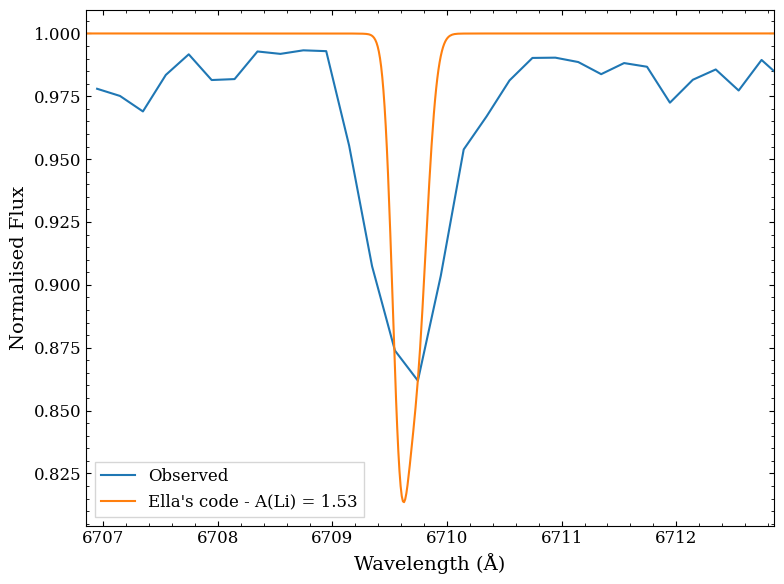

In [5]:
plt.figure(figsize=[8,6])
plt.plot(wave,flux, label='Observed')
plt.plot(pred_wl*10,pred_flux, label="Ella's code - A(Li) = 1.53")
plt.xlim(6706.851222029084, 6712.85283613651)
plt.xlabel('Wavelength (Å)')
plt.ylabel('Normalised Flux')
plt.legend(fancybox=False)
plt.tight_layout()

# plt.savefig("/data/misfit/benlowe/xshooter/results/li_lines/ella_fit_vacuum.png", dpi=300, bbox_inches='tight')